# Bank of the Future: data analysis

This notebook analyzes the app's own MySQL database, built with `flask --app bank setup-db --fresh --simulate`: two years of activity (October 2024 to September 2026) from about 2,000 customers, created by the app's own rules.

The SQL in [`queries/`](queries/) answers *what happened*. This notebook goes further with Python:

1. **Explore**: growth, how unequal balances are, how long check reviews take, and whether customers stay
2. **Test**: whether the gaps the SQL found are real or just chance
3. **Predict**: which active customers are about to stop using the bank

**To run it:** start MySQL, activate the project's `.venv`, run `pip install -r analysis/requirements.txt`, then open this notebook in VS Code (or run `jupyter notebook`). It reads the database settings from the app's `.env`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymysql
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pymysql.constants import FIELD_TYPE
from pymysql.converters import conversions

sys.path.insert(0, str(Path.cwd().parent))  # the project root, for the app's database settings
from bank import config

# The app's database, with DECIMAL money read as floats so pandas can do math on it
c = config.DB
db = pymysql.connect(host=c['host'], port=c['port'], user=c['user'], password=c['password'], database=c['name'],
                     conv={**conversions, FIELD_TYPE.NEWDECIMAL: float})


def query(sql):
    with db.cursor() as cursor:
        cursor.execute(sql)
        return pd.DataFrame(cursor.fetchall(), columns=[column[0] for column in cursor.description])


def run(name):
    """Runs one of the SQL files in queries/."""
    return query((Path('queries') / name).read_text())


# Quiet axes and gridlines so the data stands out
SURFACE, INK, MUTED, BLUE, ORANGE, RED = '#fcfcfb', '#0b0b0b', '#898781', '#2a78d6', '#eb6834', '#e34948'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'DejaVu Sans'],
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.labelcolor': '#52514e', 'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 1,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 2,
})
millions = FuncFormatter(lambda v, _: f'${v / 1e6:.0f}M')
print(query('SELECT (SELECT COUNT(*) FROM users) AS customers, (SELECT COUNT(*) FROM transactions) AS transactions,'
            ' (SELECT MIN(created_at) FROM transactions) AS first, (SELECT MAX(created_at) FROM transactions) AS last').T)

                                0
customers                    2002
transactions               153909
first         2024-10-05 15:49:53
last          2026-09-30 23:56:06


## 1. Explore

### How fast is the bank growing?

From SQL query 01. Money held and signups are on different scales, so they get two charts rather than one chart with two y-axes.

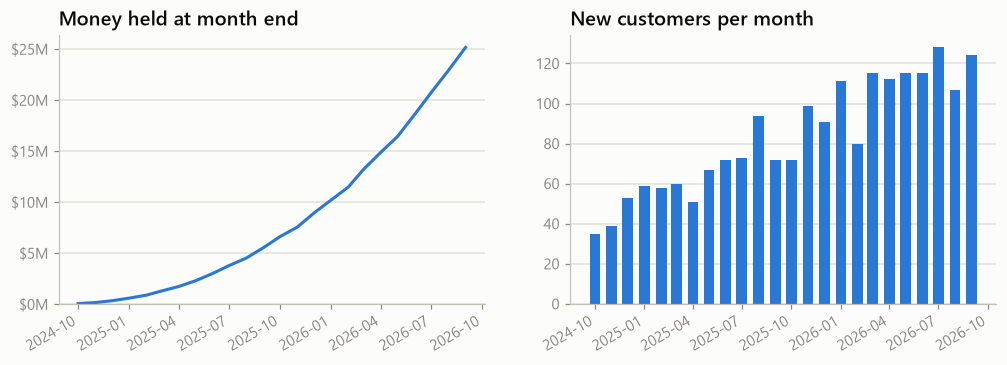

In [2]:
growth = run('01_monthly_growth.sql')
growth['month'] = pd.to_datetime(growth['month'])

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(growth['month'], growth['money_held'], color=BLUE)
left.yaxis.set_major_formatter(millions)
left.set(title='Money held at month end', ylim=(0, None))
right.bar(growth['month'], growth['new_customers'], width=20, color=BLUE)
right.set(title='New customers per month')
for ax in (left, right):
    ax.grid(axis='x', visible=False)
fig.autofmt_xdate()
plt.show()

### How unequal are balances?

SQL query 03 found the top 10% of customers hold 39% of the money. A **Lorenz curve** shows the whole distribution in one line: customers sorted from smallest balance to largest, against the share of money they hold together. The **Gini coefficient** sums it up in one number: 0 means everyone holds the same, 1 means one customer holds everything.

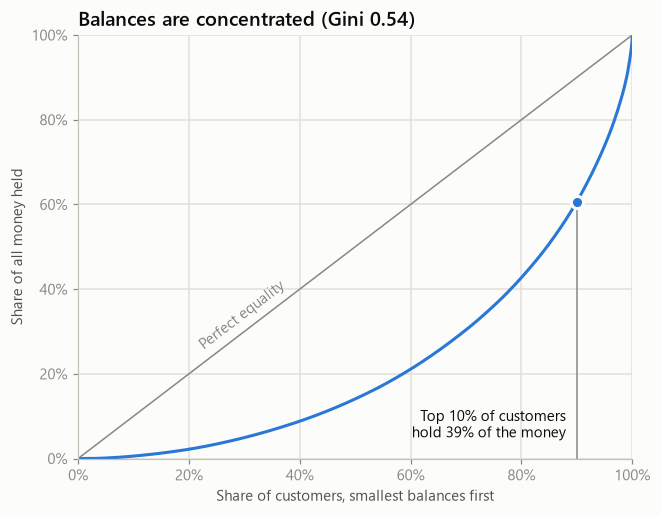

Gini coefficient: 0.543   Median customer balance: $7,595


In [3]:
balances = np.sort(query('SELECT SUM(balance) AS balance FROM accounts GROUP BY user_id')['balance'].to_numpy())
n = len(balances)
share_of_customers = np.r_[0, np.arange(1, n + 1) / n]
share_of_money = np.r_[0, balances.cumsum() / balances.sum()]
gini = 2 * np.sum(np.arange(1, n + 1) * balances) / (n * balances.sum()) - (n + 1) / n
top_10_share = 1 - share_of_money[int(n * 0.9)]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(share_of_customers, share_of_money, color=BLUE)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.text(0.3, 0.33, 'Perfect equality', color=MUTED, rotation=45, transform_rotates_text=True, rotation_mode='anchor', ha='center')
ax.plot([0.9, 0.9], [0, 1 - top_10_share], color=MUTED, linewidth=1)
ax.plot(0.9, 1 - top_10_share, 'o', color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.text(0.88, 0.05, f'Top 10% of customers\nhold {top_10_share:.0%} of the money', color=INK, ha='right')
ax.set(title=f'Balances are concentrated (Gini {gini:.2f})', xlabel='Share of customers, smallest balances first',
       ylabel='Share of all money held', xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print(f'Gini coefficient: {gini:.3f}   Median customer balance: ${np.median(balances):,.0f}')

The curve bows far below the equality line. A Gini of 0.54 is high: for comparison, US household income is around 0.49. A few large customers matter a lot, because losing one of them costs as much money as losing dozens of typical ones.

### How long do check reviews take?

Reviewers work weekdays from 9:00 to 17:00. Each line shows the spread of waits for checks sent on that day: the dot is the median, and the bar runs from the 10th to the 90th percentile.

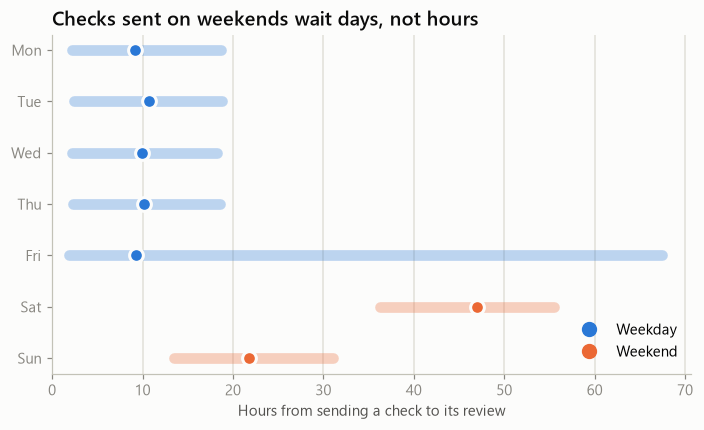

,p10_hours,median_hours,p90_hours
day_sent,,,
Mon,2.3,9.2,18.6
Tue,2.4,10.7,18.8
Wed,2.2,9.9,18.3
Thu,2.3,10.1,18.6
Fri,1.9,9.3,67.4
Sat,36.3,47.0,55.5
Sun,13.5,21.8,31.1


In [4]:
deposits = query('''
    SELECT t.created_at, t.amount, t.status, d.reviewed_by, d.reviewed_at
    FROM transactions t JOIN check_deposits d ON d.transaction_id = t.id
    WHERE d.reviewed_at IS NOT NULL''')
deposits['hours'] = (deposits['reviewed_at'] - deposits['created_at']).dt.total_seconds() / 3600
deposits['day_sent'] = deposits['created_at'].dt.day_name().str[:3]
deposits['weekend'] = deposits['created_at'].dt.day_of_week >= 5

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
spread = deposits.groupby('day_sent')['hours'].quantile([0.1, 0.5, 0.9]).unstack().loc[days]
spread.columns = ['p10_hours', 'median_hours', 'p90_hours']

fig, ax = plt.subplots(figsize=(7.5, 4))
for i, (day, row) in enumerate(spread.iterrows()):
    color = ORANGE if day in ('Sat', 'Sun') else BLUE
    ax.plot([row['p10_hours'], row['p90_hours']], [i, i], color=color, alpha=0.3, linewidth=7, solid_capstyle='round')
    ax.plot(row['median_hours'], i, 'o', color=color, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_yticks(range(len(days)), days)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set(title='Checks sent on weekends wait days, not hours', xlabel='Hours from sending a check to its review', xlim=(0, None))
ax.legend(handles=[Line2D([], [], marker='o', linestyle='', color=c, markersize=9, label=l)
                   for c, l in [(BLUE, 'Weekday'), (ORANGE, 'Weekend')]], frameon=False, loc='lower right')
plt.show()
spread.round(1)

Monday to Thursday checks are reviewed within a working day. Saturday's median wait is 47 hours, because nothing moves until Monday morning. Friday has the widest spread: a check sent Friday morning clears that afternoon, but one sent Friday evening waits all weekend.

### Do customers stay?

From SQL query 06: each row is the month a group of customers signed up, each column is months since then, and the shade is the share of that group still moving money. Month 0 is partial, since customers join throughout the month.

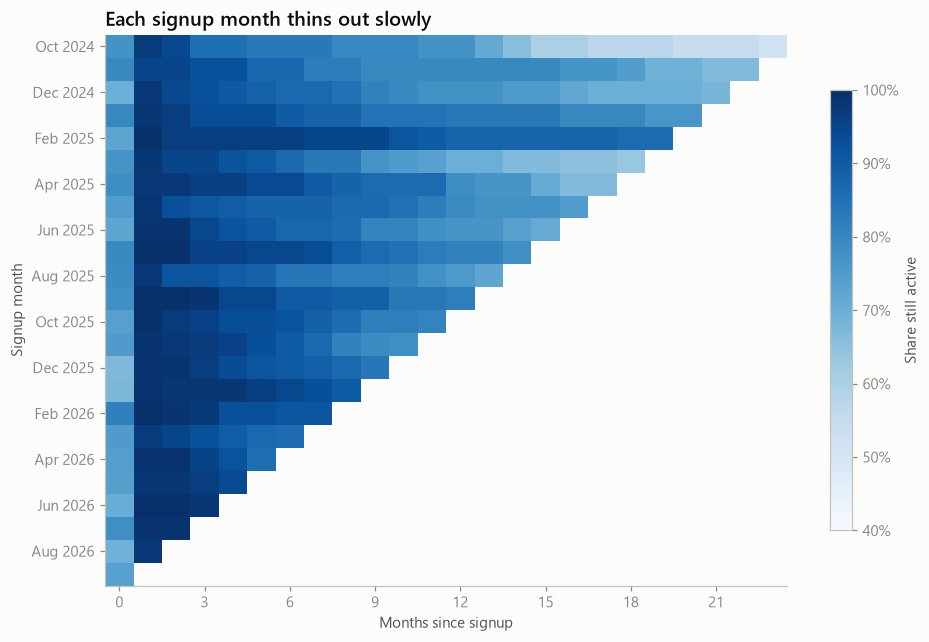

Average share active 12 months after signup: 79%


In [5]:
cohorts = run('06_cohort_retention.sql')
grid = cohorts.pivot(index='cohort', columns='months_since_signup', values='retention').astype(float)

fig, ax = plt.subplots(figsize=(10, 6.5))
image = ax.imshow(grid, cmap='Blues', vmin=0.4, vmax=1, aspect='auto')
ax.set_xticks(range(0, grid.shape[1], 3), grid.columns[::3])
ax.set_yticks(range(0, grid.shape[0], 2), [pd.Timestamp(c).strftime('%b %Y') for c in grid.index[::2]])
ax.grid(False)
ax.set(title='Each signup month thins out slowly', xlabel='Months since signup', ylabel='Signup month')
fig.colorbar(image, ax=ax, format=PercentFormatter(1), label='Share still active', shrink=0.8)
plt.show()
print('Average share active 12 months after signup:', f"{grid[12].mean():.0%}")

Nearly everyone is active in their first full month, and about 79% are still active a year later. Customers fade out gradually rather than leaving right after joining, so keeping customers is less about onboarding and more about noticing when established customers go quiet.

## 2. Test: real effects, or chance?

The SQL found two gaps: weekend checks wait longer (query 07), and some reviewers deny more checks than others (query 09). Any two groups differ a little by luck. A statistical test asks: *if there were really no difference, how likely would a gap this big be?* That probability is the **p-value**, and below 0.05 is the usual bar for calling a difference real.

### Do weekend checks really wait longer?

Waiting times are skewed (most are short and a few are very long), so this uses the **Mann-Whitney U test**, which compares the ranks of the waits instead of their averages and doesn't assume a bell curve.

In [6]:
from matplotlib.ticker import MultipleLocator
from scipy import stats


def p_value(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


weekday = deposits.loc[~deposits['weekend'], 'hours']
weekend = deposits.loc[deposits['weekend'], 'hours']
u, p = stats.mannwhitneyu(weekend, weekday, alternative='greater')
print(f'Median wait: weekday {weekday.median():.1f} hours, weekend {weekend.median():.1f} hours')
print(f'Mann-Whitney U = {u:,.0f}, {p_value(p)}')
print(f'A random weekend check waits longer than a random weekday check {u / (len(weekend) * len(weekday)):.0%} of the time')

Median wait: weekday 9.9 hours, weekend 32.5 hours
Mann-Whitney U = 250,863,588, p < 0.001
A random weekend check waits longer than a random weekday check 86% of the time


**Yes, beyond doubt** (p < 0.001). The median weekend check waits 32.5 hours against 9.9 on a weekday, and a random weekend check waits longer than a random weekday check 86% of the time. With about 100 weekend checks a week, a short Saturday review shift would remove the longest waits.

### Do some reviewers really deny more checks?

A **chi-square test** checks whether a check's outcome (approved or denied) depends on who reviewed it. Query 08 showed big checks are denied more often, so the test runs separately for checks under \$2,500 and checks of \$2,500 or more. That way, a reviewer who happened to get bigger checks can't skew the result.

In [7]:
deposits['denied'] = deposits['status'] == 'Denied'
deposits['large'] = deposits['amount'] >= 2500
for large, group in deposits.groupby('large'):
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(group['reviewed_by'], group['denied']))
    label = 'Checks of $2,500 or more' if large else 'Checks under $2,500'
    print(f'{label}: chi-square = {chi2:.1f} ({dof} degrees of freedom), {p_value(p)}')

Checks under $2,500: chi-square = 125.9 (5 degrees of freedom), p < 0.001
Checks of $2,500 or more: chi-square = 65.5 (5 degrees of freedom), p < 0.001


The chart shows each reviewer's denial rate with a **95% confidence interval**: the range their true rate most likely falls in, given how many checks they've reviewed. Where a reviewer's interval doesn't reach the team rate, the difference is unlikely to be chance.

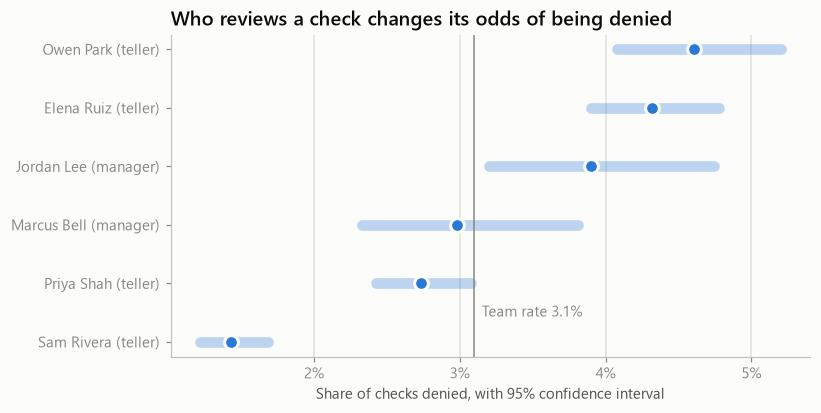

,reviews,denied,denial_rate,ci_low,ci_high,large_check_share
reviewer,,,,,,
Sam Rivera (teller),9837,141,0.014,0.012,0.017,0.160
Priya Shah (teller),9517,260,0.027,0.024,0.031,0.155
Marcus Bell (manager),2045,61,0.030,0.023,0.038,0.153
Jordan Lee (manager),2437,95,0.039,0.032,0.047,0.162
Elena Ruiz (teller),8198,354,0.043,0.039,0.048,0.149
Owen Park (teller),5360,247,0.046,0.041,0.052,0.161


In [8]:
staff = query("SELECT id, CONCAT(first_name, ' ', last_name) AS name, tier FROM employees").set_index('id')
rates = deposits.groupby('reviewed_by').agg(reviews=('denied', 'size'), denied=('denied', 'sum'),
                                            large_check_share=('large', 'mean'))
rates['denial_rate'] = rates['denied'] / rates['reviews']
intervals = [stats.binomtest(int(d), int(n)).proportion_ci(method='wilson') for d, n in zip(rates['denied'], rates['reviews'])]
rates['ci_low'] = [i.low for i in intervals]
rates['ci_high'] = [i.high for i in intervals]
rates['reviewer'] = [f"{staff.loc[e, 'name']} ({'teller' if staff.loc[e, 'tier'] == 1 else 'manager'})" for e in rates.index]
rates = rates.sort_values('denial_rate')
team_rate = rates['denied'].sum() / rates['reviews'].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (_, row) in enumerate(rates.iterrows()):
    ax.plot([row['ci_low'], row['ci_high']], [i, i], color=BLUE, alpha=0.3, linewidth=7, solid_capstyle='round')
    ax.plot(row['denial_rate'], i, 'o', color=BLUE, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(team_rate, color=MUTED, linewidth=1)
ax.text(team_rate, 0.5, f'  Team rate {team_rate:.1%}', color=MUTED, va='center')
ax.set_yticks(range(len(rates)), rates['reviewer'])
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_locator(MultipleLocator(0.01))  # ticks on whole percents
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(title='Who reviews a check changes its odds of being denied', xlabel='Share of checks denied, with 95% confidence interval')
plt.show()
rates.set_index('reviewer')[['reviews', 'denied', 'denial_rate', 'ci_low', 'ci_high', 'large_check_share']].round(3)

**Yes.** For both check sizes, p < 0.001: whether a check is denied depends on who reviews it. Sam Rivera denies 1.4% of checks (interval 1.2% to 1.7%) and Owen Park 4.6% (4.1% to 5.2%), more than three times as often, and their intervals are far apart. Every reviewer gets about the same share of large checks (15-16%), so the gap isn't about which checks they see. **Recommendation:** written denial criteria, plus regular sessions where reviewers judge the same sample of checks and compare their decisions.

## 3. Predict: who is about to go quiet?

SQL query 05 found \$2.5M sitting with dormant customers. Reaching people *before* they leave is cheaper than winning them back, so the question is: **looking at the bank on 1 July 2026, can we tell which active customers will stop moving money over the next three months?**

The features are built in SQL from data *before* the snapshot date only, so the model never sees the future it's predicting.

In [9]:
FEATURES_SQL = '''
WITH own_moves AS (   -- money the customer moved themselves
    SELECT a.user_id, t.created_at, t.type, t.status, t.amount
    FROM transactions t
    JOIN accounts a ON a.account_number = t.account_number
    WHERE t.type IN ('Deposit', 'Withdrawal', 'Transfer Out')
),
history AS (
    SELECT user_id,
           MAX(created_at) AS last_active_at,
           SUM(created_at >= TIMESTAMP('{snapshot}') - INTERVAL 30 DAY) AS moves_last_30_days,
           SUM(created_at < TIMESTAMP('{snapshot}') - INTERVAL 30 DAY
               AND created_at >= TIMESTAMP('{snapshot}') - INTERVAL 90 DAY) AS moves_prior_60_days,
           SUM(type = 'Deposit' AND status = 'Denied') AS denied_checks,
           AVG(CASE WHEN type = 'Deposit' THEN amount END) AS avg_check
    FROM own_moves
    WHERE created_at < TIMESTAMP('{snapshot}')
    GROUP BY user_id
),
balances AS (   -- money held at the snapshot: everything posted before it
    SELECT a.user_id, SUM(t.amount) AS balance
    FROM transactions t
    JOIN accounts a ON a.account_number = t.account_number
    LEFT JOIN check_deposits d ON d.transaction_id = t.id
    WHERE t.status = 'Processed' AND COALESCE(d.reviewed_at, t.created_at) < TIMESTAMP('{snapshot}')
    GROUP BY a.user_id
),
savers AS (
    SELECT user_id, MAX(type = 'Savings') AS has_savings
    FROM accounts
    WHERE created_at < TIMESTAMP('{snapshot}')
    GROUP BY user_id
)
SELECT u.id AS customer_id,
       CONCAT(u.first_name, ' ', u.last_name) AS name,
       TIMESTAMPDIFF(DAY, u.created_at, TIMESTAMP('{snapshot}')) AS tenure_days,
       TIMESTAMPDIFF(MINUTE, h.last_active_at, TIMESTAMP('{snapshot}')) / 1440 AS days_since_active,
       h.moves_last_30_days, h.moves_prior_60_days, h.denied_checks, h.avg_check,
       COALESCE(b.balance, 0) AS balance,
       COALESCE(s.has_savings, 0) AS has_savings,
       NOT EXISTS (SELECT 1 FROM own_moves m WHERE m.user_id = u.id AND m.created_at >= TIMESTAMP('{snapshot}')) AS went_dormant
FROM users u
JOIN history h ON h.user_id = u.id
LEFT JOIN balances b ON b.user_id = u.id
LEFT JOIN savers s ON s.user_id = u.id
WHERE u.created_at < TIMESTAMP('{snapshot}') - INTERVAL 90 DAY        -- at least 90 days of history
  AND h.last_active_at >= TIMESTAMP('{snapshot}') - INTERVAL 90 DAY  -- and still active at the snapshot
'''
FEATURES = {
    'days_since_active': 'Days since last activity',
    'moves_last_30_days': 'Transactions in the last 30 days',
    'moves_prior_60_days': 'Transactions 30-90 days before',
    'tenure_days': 'Days as a customer',
    'denied_checks': 'Denied checks',
    'avg_check': 'Average check size',
    'balance': 'Balance',
    'has_savings': 'Has a savings account',
}

snapshot = query(FEATURES_SQL.format(snapshot='2026-07-01'))
print(f"{len(snapshot):,} active customers on 1 July 2026; {snapshot['went_dormant'].mean():.1%} went quiet by the end of September")

1,135 active customers on 1 July 2026; 6.4% went quiet by the end of September


The model is a **logistic regression**: it weighs each feature to estimate a probability of going quiet. It's trained on 70% of customers and scored on the other 30%, which it never saw.

Accuracy is measured with **ROC AUC**: the chance the model ranks a customer who left above one who stayed. 0.5 is a coin flip and 1.0 is perfect. The baseline is the simplest possible rule: rank customers by how long it's been since they last moved money.

To see which features the model really relies on, each one is scrambled in turn on the test customers (**permutation importance**). If the AUC drops, the feature mattered; if not, the model was getting nothing from it.

Model ROC AUC: 0.945
"Days since last activity" alone: 0.919


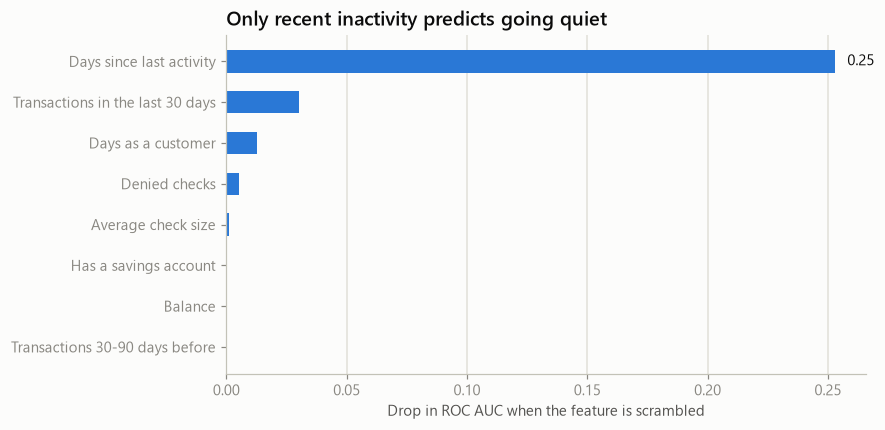

,auc_drop
Transactions 30-90 days before,-0.005
Balance,-0.003
Has a savings account,0.000
Average check size,0.001
Denied checks,0.005
Days as a customer,0.013
Transactions in the last 30 days,0.030
Days since last activity,0.253


In [10]:
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = snapshot[list(FEATURES)].astype(float).fillna(0)
y = snapshot['went_dormant'].astype(bool)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
model_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
rule_auc = roc_auc_score(y_test, X_test['days_since_active'])
print(f'Model ROC AUC: {model_auc:.3f}')
print(f'"Days since last activity" alone: {rule_auc:.3f}')

importance = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=42)
auc_drop = pd.Series(importance.importances_mean, index=[FEATURES[f] for f in FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(auc_drop.index, auc_drop.clip(lower=0), height=0.55, color=BLUE)
ax.text(auc_drop.iloc[-1] + 0.005, len(auc_drop) - 1, f'{auc_drop.iloc[-1]:.2f}', va='center', color=INK)
ax.grid(axis='y', visible=False)
ax.set(title='Only recent inactivity predicts going quiet', xlabel='Drop in ROC AUC when the feature is scrambled')
plt.show()
auc_drop.round(3).to_frame('auc_drop')

**Recency is what predicts it.** "Days since last activity" on its own reaches a ROC AUC of 0.92, and the model gets to 0.95 mainly by also counting transactions in the last 30 days. Scrambling days-since-activity drops the AUC by 0.25; balance, savings, denied checks and check size barely matter. So the bank doesn't need a complex model: a weekly report of customers who have gone quiet, ranked by how long, does most of the job. (About 70 customers went quiet in this window, so small differences between the weaker features aren't reliable.)

### Who to call this week

Applying the same features at the end of the data (1 October 2026) gives a ranked list of active customers who look like they're slipping away, with the money they hold.

In [11]:
today = query(FEATURES_SQL.format(snapshot='2026-10-01'))
today['risk'] = model.predict_proba(today[list(FEATURES)].astype(float).fillna(0))[:, 1]
likely = today['risk'] > 0.5
print(f"{likely.sum()} of {len(today):,} active customers are more likely than not to go quiet, holding ${today.loc[likely, 'balance'].sum():,.0f}")
today.sort_values('risk', ascending=False).head(10)[['customer_id', 'name', 'risk', 'days_since_active', 'moves_last_30_days', 'balance']].round(2)

79 of 1,401 active customers are more likely than not to go quiet, holding $1,414,196


,customer_id,name,risk,days_since_active,moves_last_30_days,balance
1194,2444,Liam Lewis,1.0,88.71,0.0,1755.55
978,2214,Amara Anderson,1.0,87.33,0.0,9348.93
823,2045,Elena Scott,1.0,86.74,0.0,23690.36
1231,2482,Tyler White,1.0,83.00,0.0,881.52
897,2124,Grace Allen,1.0,85.35,0.0,4278.41
696,1906,Aisha Scott,1.0,81.83,0.0,1923.44
1065,2309,Jonah Chen,1.0,78.99,0.0,3870.49
625,1817,Wei Lee,1.0,80.48,0.0,3905.85
993,2230,Daniel Brown,1.0,75.72,0.0,4954.46
865,2091,Chloe Williams,1.0,76.30,0.0,8660.10


79 active customers are more likely than not to go quiet, and together they hold \$1.4M. None of the top ten have moved money for 11 to 13 weeks. **Recommendation:** contact customers soon after they go quiet, before they cross the 90-day line, starting with the largest balances.